<a href="https://colab.research.google.com/github/Glaze0/Assignment/blob/main/20_unsupervised_kmeans_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

!gdown 1vyygxUsAS6qtC5o9bkDkoEzxRwrV2UtT

customers = pd.read_csv("mall_customers.csv")



Downloading...
From: https://drive.google.com/uc?id=1vyygxUsAS6qtC5o9bkDkoEzxRwrV2UtT
To: /content/mall_customers.csv
100% 1.82k/1.82k [00:00<00:00, 6.11MB/s]


In [ ]:
customers.head()

,age,income,spending
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [ ]:
customers.shape

(200, 3)

In [ ]:
X = customers[["income", "spending"]]

In [ ]:
def show(points, labels=None, centres=None, title=""):     #  draws customers and centres
    points = pd.DataFrame(points)
    plt.figure(figsize=(5, 4))
    plt.scatter(points.iloc[:, 0], points.iloc[:, 1], c=labels, cmap="tab10" if labels is not None else None, s=20)
    if centres is not None:
        plt.scatter(centres[:, 0], centres[:, 1], c="black", marker="X", s=200)
    plt.xlabel(points.columns[0])
    plt.ylabel(points.columns[1])
    plt.title(title)
    plt.show()

(200, 3)


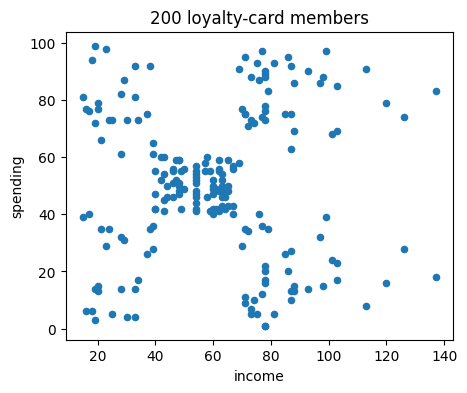

In [ ]:
print(customers.shape)
show(X, title="200 loyalty-card members")       # how many groups do YOU see?

In [ ]:
model = KMeans(n_clusters=5)
model.fit(X) # learns -> centroids

KMeans(n_clusters=5)

In [ ]:
model.cluster_centers_

array([[ 48.16831683,  43.3960396 ],
       [ 78.03571429,  81.89285714],
       [ 25.72727273,  79.36363636],
       [ 87.        ,  18.63157895],
       [108.18181818,  82.72727273]])

In [ ]:
model.labels_

array([0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2,
       0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 0,
       0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4], dtype=int32)

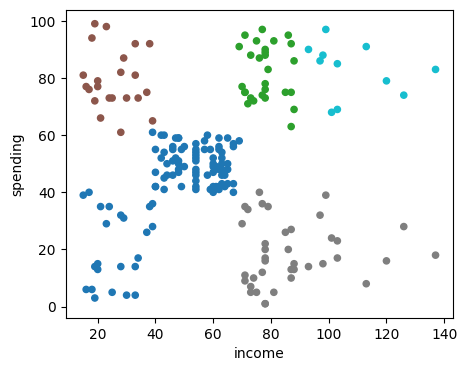

In [ ]:
show(X, model.labels_)

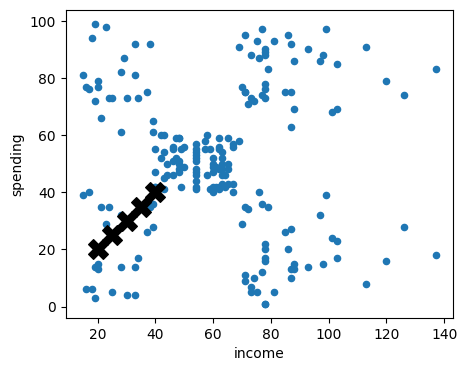

In [ ]:
start = np.array([[20, 20], [25, 25], [30, 30], [35, 35], [40, 40]])
show(X, centres=start)

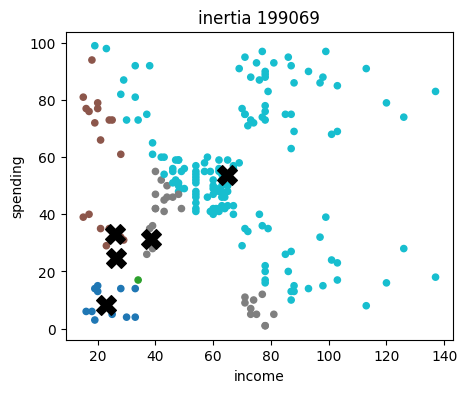

In [ ]:
model = KMeans(n_clusters=5, init=start, n_init=1, max_iter=1).fit(X)
show(X, model.labels_, model.cluster_centers_,  f"inertia {model.inertia_:.0f}")

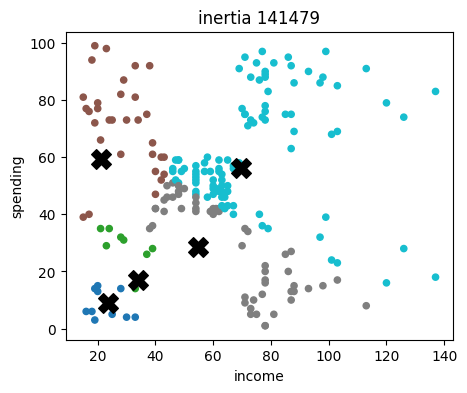

In [ ]:
model = KMeans(n_clusters=5, init=start, n_init=1, max_iter=2).fit(X)
show(X, model.labels_, model.cluster_centers_,  f"inertia {model.inertia_:.0f}")

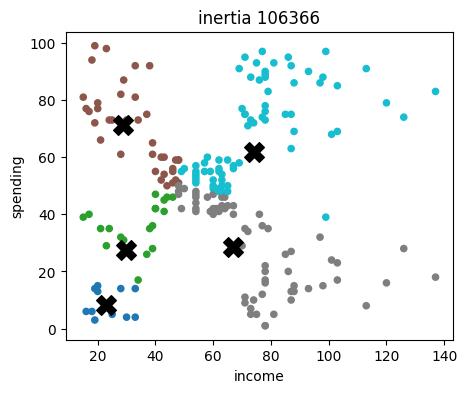

In [ ]:
model = KMeans(n_clusters=5, init=start, n_init=1, max_iter=3).fit(X)
show(X, model.labels_, model.cluster_centers_,  f"inertia {model.inertia_:.0f}")

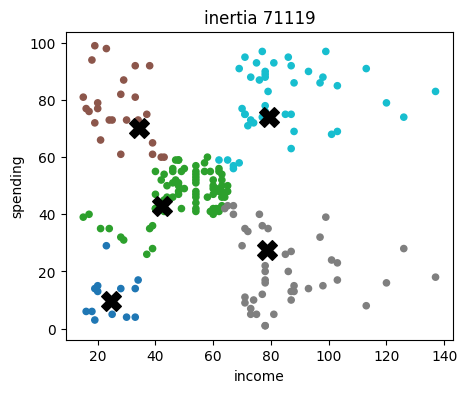

In [ ]:
model = KMeans(n_clusters=5, init=start, n_init=1, max_iter=5).fit(X)
show(X, model.labels_, model.cluster_centers_,  f"inertia {model.inertia_:.0f}")

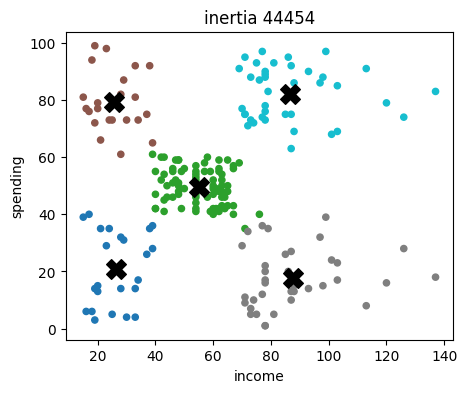

In [ ]:
model = KMeans(n_clusters=5, init=start, n_init=1, max_iter=10).fit(X)
show(X, model.labels_, model.cluster_centers_,  f"inertia {model.inertia_:.0f}")

In [ ]:
model.predict([[30,30]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


array([0], dtype=int32)

In [ ]:
model.cluster_centers_

array([[26.30434783, 20.91304348],
       [55.0875    , 49.7125    ],
       [25.72727273, 79.36363636],
       [87.75      , 17.58333333],
       [86.53846154, 82.12820513]])

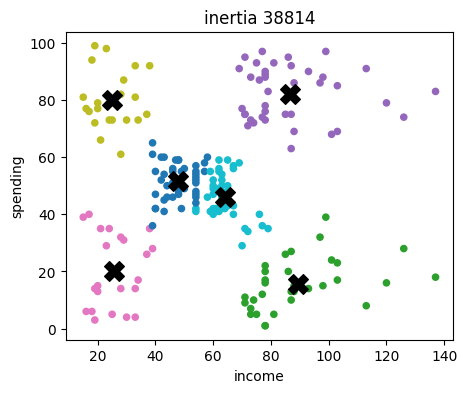

In [ ]:
model = KMeans(n_clusters=6, max_iter=10).fit(X)
show(X, model.labels_, model.cluster_centers_,  f"inertia {model.inertia_:.0f}")

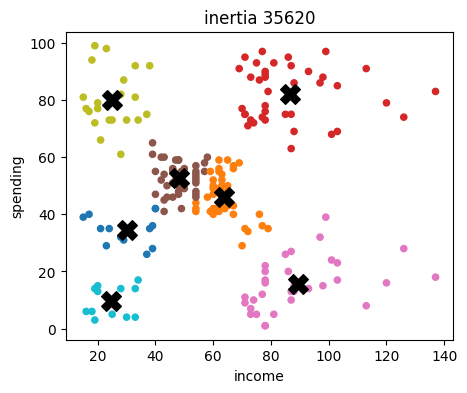

In [ ]:
model = KMeans(n_clusters=7, max_iter=10).fit(X)
show(X, model.labels_, model.cluster_centers_,  f"inertia {model.inertia_:.0f}")

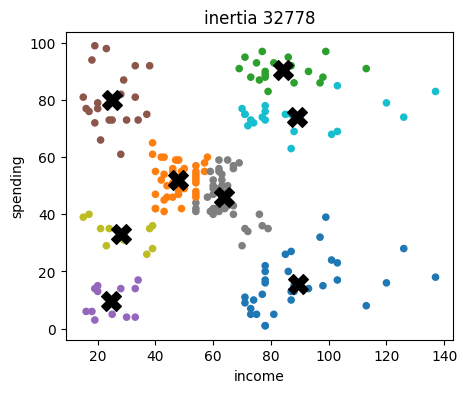

In [ ]:
model = KMeans(n_clusters=8, max_iter=10).fit(X)
show(X, model.labels_, model.cluster_centers_,  f"inertia {model.inertia_:.0f}")

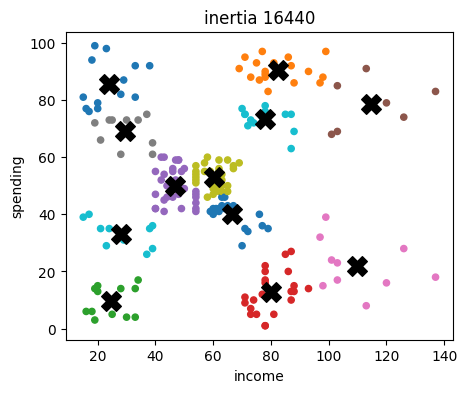

In [ ]:
model = KMeans(n_clusters=12, max_iter=10).fit(X)
show(X, model.labels_, model.cluster_centers_,  f"inertia {model.inertia_:.0f}")

## Elbow Method

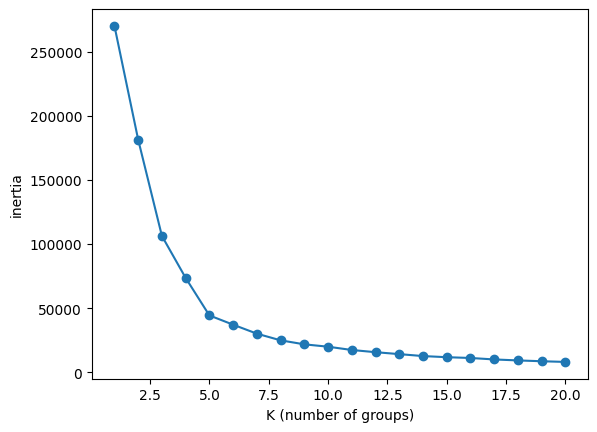

In [ ]:
inertias = []
for k in range(1, 21):
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(model.inertia_)

plt.plot(range(1, 21), inertias, marker="o")
plt.xlabel("K (number of groups)")
plt.ylabel("inertia")
plt.show()


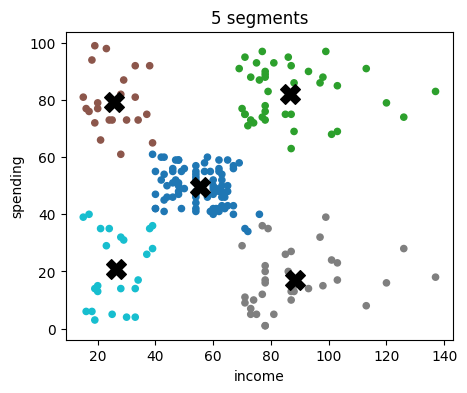

In [ ]:
model = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X)
show(X, model.labels_, model.cluster_centers_, "5 segments")

In [ ]:
customers["segment"] = model.labels_                       # the group number K-Means gave each member
customers.head()

,age,income,spending,segment
0,19,15,39,4
1,21,15,81,2
2,20,16,6,4
3,23,16,77,2
4,31,17,40,4


In [ ]:
summary = customers.groupby("segment").mean().round(1)       # the average member of each group
summary["members"] = customers["segment"].value_counts()
summary

,age,income,spending,members
segment,,,,
0,42.7,55.3,49.5,81
1,32.7,86.5,82.1,39
2,25.3,25.7,79.4,22
3,41.1,88.2,17.1,35
4,45.2,26.3,20.9,23


In [ ]:
# Q- The elbow sits between 4 and 5, and marketing can only run 4 campaigns. What do you do?
# Q- Why is "lowest inertia" a useless rule for choosing K?

In [ ]:
X_rupees = X.copy()
X_rupees["income"] = X["income"] * 1000

In [ ]:
X_rupees.head()

,income,spending
0,15000,39
1,15000,81
2,16000,6
3,16000,77
4,17000,40


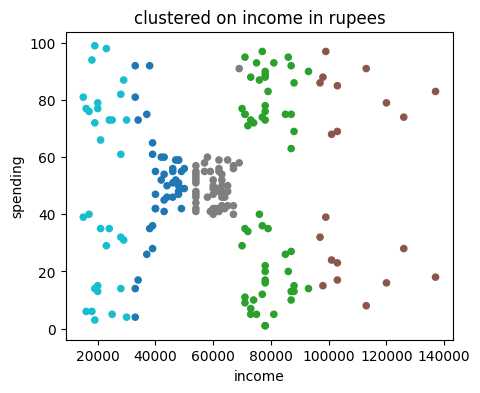

In [ ]:
rupee_model = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X_rupees)
show(X_rupees, rupee_model.labels_, title="clustered on income in rupees")

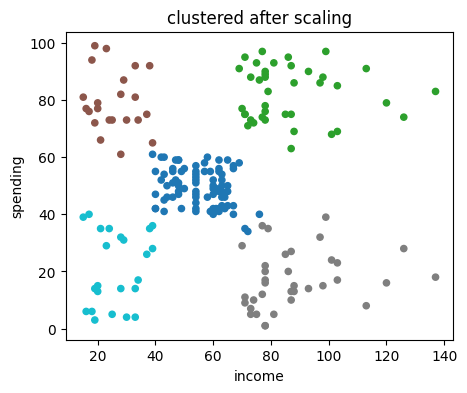

In [ ]:
X_rupees_scaled = StandardScaler().fit_transform(X_rupees)

scaled_model = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X_rupees_scaled)
show(X, scaled_model.labels_, title="clustered after scaling")

In [ ]:
from sklearn.datasets import make_moons
X_moons, _ = make_moons(n_samples=200, noise=0.05, random_state=42)

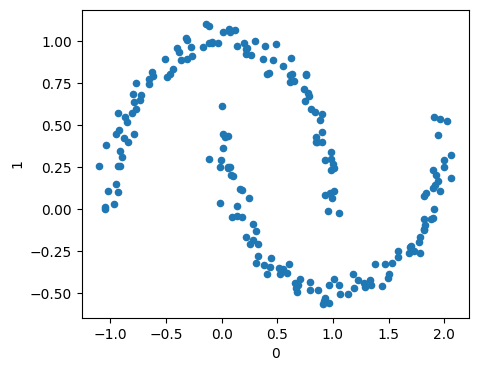

In [ ]:
show(X_moons)

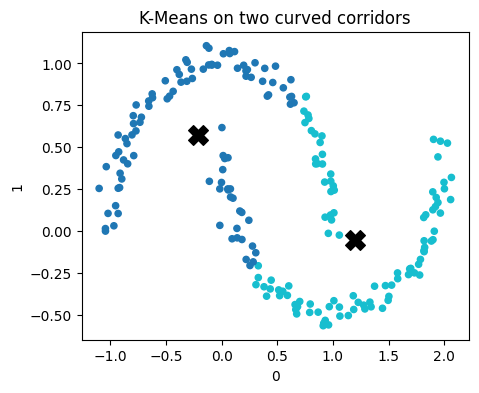

In [ ]:
moon_model = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_moons)
show(X_moons, moon_model.labels_, moon_model.cluster_centers_, "K-Means on two curved corridors")

In [ ]:
X3 = customers[["age", "income", "spending"]]
X3.head()

,age,income,spending
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [ ]:
X3_scaled = StandardScaler().fit_transform(X3)          # different units again, so scale first

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X2 = pca.fit_transform(X3_scaled)

In [ ]:
X2.shape

(200, 2)

In [ ]:
X2[:5]

array([[-0.61572002, -1.76348088],
       [-1.66579271, -1.82074695],
       [ 0.33786191, -1.67479894],
       [-1.45657325, -1.77242992],
       [-0.03846521, -1.66274012]])

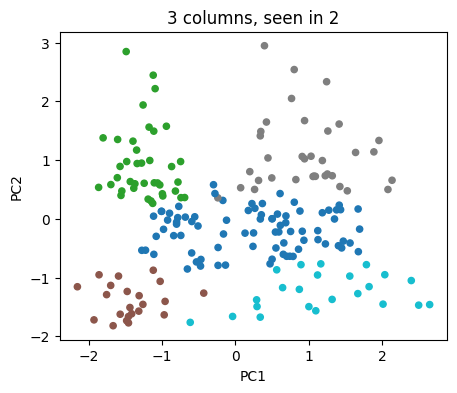

In [ ]:
X2 = pd.DataFrame(X2, columns=["PC1", "PC2"])
show(X2, customers["segment"], title="3 columns, seen in 2")